# Notebook 3 — Entrenamiento del Modelo Propio

Entrena EfficientNet-B0 sobre los segmentos etiquetados usando mel-espectrogramas como input.
La RTX 3090 con mixed precision (AMP) hace esto muy rapido.

**Proceso iterativo:**
- Ronda 1: ~50 muestras/clase -> Accuracy ~70%
- Ronda 2: +100 muestras/clase -> Accuracy ~85%
- Ronda 3: +200 muestras/clase -> Accuracy ~92%+

In [18]:
# CELDA 1 — CONFIGURACION
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

METADATA_PATH = r"C:\temporales\metadata.csv"
MODEL_DIR     = r"C:\temporales\modelos"
MODEL_NAME    = "clasificador_radio_v1.pth"

SAMPLE_RATE  = 32_000
N_MELS       = 128
N_FFT        = 2048
HOP_LENGTH   = 512
IMG_SIZE     = 224
BATCH_SIZE   = 64
EPOCHS       = 50
LR           = 3e-4
WEIGHT_DECAY = 1e-4
VAL_SPLIT    = 0.15
PATIENCE     = 8

# False = usar tambien segmentos auto-aprobados (mas datos, recomendado)
SOLO_HUMANOS = False

os.makedirs(MODEL_DIR, exist_ok=True)
print("Configuracion lista")


Configuracion lista


In [19]:
# CELDA 2 — IMPORTS Y VERIFICACION DE GPU
import torch
import torchaudio
import torchaudio.transforms as T
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.cuda.amp import autocast, GradScaler
import timm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo: {device}")
if device.type == 'cuda':
    print(f"  GPU : {torch.cuda.get_device_name(0)}")
    print(f"  VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


Dispositivo: cuda
  GPU : NVIDIA GeForce RTX 3090
  VRAM: 25.8 GB


In [20]:
# CELDA 3 — CARGAR Y REVISAR DATOS
df = pd.read_csv(METADATA_PATH)

if SOLO_HUMANOS:
    df_labeled = df[df['label_fuente'] == 'humano'].copy()
else:
    df_labeled = df[df['revisado'] == True].copy()

df_labeled = df_labeled[df_labeled['label'].notna() & (df_labeled['label'] != 'indefinido')].copy()
df_labeled = df_labeled[df_labeled['ruta_wav'].apply(
    lambda p: Path(p).exists())].copy()

print(f"Muestras disponibles: {len(df_labeled):,}")
dist = df_labeled.groupby('label').size().sort_values(ascending=False)
print(dist.to_frame('cantidad'))

CATEGORIAS   = sorted(df_labeled['label'].unique().tolist())
N_CLASES     = len(CATEGORIAS)
LABEL_TO_IDX = {c: i for i, c in enumerate(CATEGORIAS)}
IDX_TO_LABEL = {i: c for c, i in LABEL_TO_IDX.items()}
print(f"\nClases ({N_CLASES}): {CATEGORIAS}")

if dist.min() < 20:
    print("AVISO: Algunas clases tienen < 20 muestras. Etiqueta mas antes de entrenar.")


Muestras disponibles: 24,876
             cantidad
label                
locutor         12730
musica          12117
entrevistas        16
deportes           13

Clases (4): ['deportes', 'entrevistas', 'locutor', 'musica']
AVISO: Algunas clases tienen < 20 muestras. Etiqueta mas antes de entrenar.


In [21]:
# CELDA 4 — DATASET OPTIMIZADO CON CACHE EN RAM (Zero-Disk Bottleneck + Epsilon Guard)
from tqdm.notebook import tqdm

class RadioAudioDataset(Dataset):
    def __init__(self, df, label_to_idx, augment=False, cache_in_ram=True):
        self.df           = df.reset_index(drop=True)
        self.label_to_idx = label_to_idx
        self.augment      = augment
        self.cache_in_ram = cache_in_ram

        self.mel_t  = T.MelSpectrogram(
            sample_rate=SAMPLE_RATE, n_fft=N_FFT,
            hop_length=HOP_LENGTH, n_mels=N_MELS, f_max=15000)
        self.db_t   = T.AmplitudeToDB(top_db=80)

        if augment:
            self.freq_mask = T.FrequencyMasking(freq_mask_param=30)
            self.time_mask = T.TimeMasking(time_mask_param=50)

        self.cached_mels = []
        if self.cache_in_ram:
            desc = "Pre-cargando espectrogramas en RAM (Train)" if augment else "Pre-cargando espectrogramas en RAM (Val)"
            for i in tqdm(range(len(self.df)), desc=desc, leave=False):
                self.cached_mels.append(self._process_mel(i))

    def _process_mel(self, idx):
        row = self.df.iloc[idx]
        try:
            waveform, sr = torchaudio.load(row['ruta_wav'])
        except Exception:
            waveform, sr = torch.zeros(1, SAMPLE_RATE * 10), SAMPLE_RATE
        if sr != SAMPLE_RATE:
            waveform = T.Resample(sr, SAMPLE_RATE)(waveform)
        if waveform.shape[0] > 1:
            waveform = waveform.mean(dim=0, keepdim=True)
        mel = self.db_t(self.mel_t(waveform))
        mn, mx = mel.min(), mel.max()
        diff = mx - mn
        if diff > 1e-5:
            mel = 2.0 * (mel - mn) / (diff + 1e-5) - 1.0
        else:
            mel = torch.zeros_like(mel)
        mel_r = torch.nn.functional.interpolate(
            mel.unsqueeze(0), size=(IMG_SIZE, IMG_SIZE),
            mode='bilinear', align_corners=False).squeeze(0)
        return mel_r

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        if self.cache_in_ram:
            mel = self.cached_mels[idx].clone()
        else:
            mel = self._process_mel(idx)

        if self.augment:
            if torch.rand(1) > 0.5: mel = self.freq_mask(mel)
            if torch.rand(1) > 0.5: mel = self.time_mask(mel)
            mel = mel + torch.randn_like(mel) * 0.05

        label_idx = self.label_to_idx[self.df.iloc[idx]['label']]
        return mel.repeat(3, 1, 1), torch.tensor(label_idx)

print("Dataset optimizado con cache en RAM")


Dataset optimizado con cache en RAM


In [22]:
# CELDA 5 — CREAR DATALOADERS
# Fix 1: descarta clases con < 2 muestras (insuficientes para stratify)
# Fix 2: num_workers=0 en Windows+Jupyter (evita crash de procesos hijos)

import platform
NUM_WORKERS_DL = 0 if platform.system() == 'Windows' else 4

MIN_MUESTRAS_POR_CLASE = 2

counts = df_labeled['label'].value_counts()
clases_ok    = counts[counts >= MIN_MUESTRAS_POR_CLASE].index.tolist()
clases_bajas = counts[counts < MIN_MUESTRAS_POR_CLASE].index.tolist()

if clases_bajas:
    print(f"AVISO: Se excluyen {len(clases_bajas)} clase(s) con < {MIN_MUESTRAS_POR_CLASE} muestras: {clases_bajas}")
    print(f"       Etiqueta mas segmentos de esas categorias antes de entrenar.")
    df_labeled = df_labeled[df_labeled['label'].isin(clases_ok)].copy()

    CATEGORIAS   = sorted(df_labeled['label'].unique().tolist())
    N_CLASES     = len(CATEGORIAS)
    LABEL_TO_IDX = {c: i for i, c in enumerate(CATEGORIAS)}
    IDX_TO_LABEL = {i: c for c, i in LABEL_TO_IDX.items()}
    print(f"       Clases restantes ({N_CLASES}): {CATEGORIAS}\n")

train_df, val_df = train_test_split(
    df_labeled, test_size=VAL_SPLIT, stratify=df_labeled['label'], random_state=42)

train_ds = RadioAudioDataset(train_df, LABEL_TO_IDX, augment=True)
val_ds   = RadioAudioDataset(val_df,   LABEL_TO_IDX, augment=False)

lc = train_df['label'].map(LABEL_TO_IDX).value_counts().sort_index()
sw = train_df['label'].map(LABEL_TO_IDX).map((1.0 / lc).to_dict()).values
sampler = WeightedRandomSampler(torch.DoubleTensor(sw), len(train_ds), replacement=True)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=NUM_WORKERS_DL, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE * 2, shuffle=False,
                          num_workers=NUM_WORKERS_DL, pin_memory=True)

print(f"num_workers = {NUM_WORKERS_DL} ({'Windows: sin multiprocessing' if NUM_WORKERS_DL == 0 else 'multiprocessing activo'})")
print(f"Train: {len(train_ds):,} muestras, {len(train_loader)} batches")
print(f"Val  : {len(val_ds):,} muestras, {len(val_loader)} batches")



Pre-cargando espectrogramas en RAM (Train):   0%|          | 0/21144 [00:00<?, ?it/s]

Pre-cargando espectrogramas en RAM (Val):   0%|          | 0/3732 [00:00<?, ?it/s]

num_workers = 0 (Windows: sin multiprocessing)
Train: 21,144 muestras, 330 batches
Val  : 3,732 muestras, 30 batches


In [23]:
# CELDA 6 — MODELO EFFICIENTNET-B0 (Con re-entrenamiento/Fine-tuning continuo)
model = timm.create_model('efficientnet_b0', pretrained=True, num_classes=N_CLASES, drop_rate=0.4)

best_path = os.path.join(MODEL_DIR, MODEL_NAME)
if Path(best_path).exists():
    try:
        ckpt = torch.load(best_path, map_location=device)
        saved_label_map = ckpt.get('label_to_idx', {})
        if len(saved_label_map) == N_CLASES:
            model.load_state_dict(ckpt['model_state'])
            print(f"✓ Pesos previos cargados desde {best_path} (Continuando re-entrenamiento desde checkpoint existente)")
        else:
            print(f"Aviso: El numero de clases cambio ({len(saved_label_map)} -> {N_CLASES}). Inicializando modelo desde ImageNet.")
    except Exception as e:
        print(f"No se pudieron cargar pesos previos ({e}). Entrenando desde ImageNet.")
else:
    print("Iniciando entrenamiento desde cero a partir de pesos pre-entrenados ImageNet.")

model = model.to(device)

# Congelar backbone, solo entrenar clasificador al inicio
for p in model.parameters(): p.requires_grad = False
for p in model.classifier.parameters(): p.requires_grad = True

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"EfficientNet-B0 listo | Total params: {n_total:,} | Entrenables: {n_train:,}")


✓ Pesos previos cargados desde C:\temporales\modelos\clasificador_radio_v1.pth (Continuando re-entrenamiento desde checkpoint existente)
EfficientNet-B0 listo | Total params: 4,012,672 | Entrenables: 5,124


In [24]:
# CELDA 7 — TRAINING LOOP CON EARLY STOPPING Y MIXED PRECISION
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                        lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler    = GradScaler()

UNFREEZE_EPOCH = 5

def run_epoch(loader, training=True):
    model.train() if training else model.eval()
    total_loss = correct = total = 0
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for bx, by in loader:
            bx = bx.to(device, non_blocking=True)
            by = by.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad()
                with autocast():
                    out  = model(bx); loss = criterion(out, by)
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update()
            else:
                with autocast():
                    out  = model(bx); loss = criterion(out, by)
            total_loss += loss.item() * len(by)
            correct    += (out.argmax(1) == by).sum().item()
            total      += len(by)
    return total_loss / total, correct / total

history = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc']}
best_val_acc = 0.0; patience_cnt = 0
best_path = os.path.join(MODEL_DIR, MODEL_NAME)

print(f"Entrenando en {device} ({EPOCHS} epocas max, patience={PATIENCE})")
print("-" * 65)

for epoch in range(1, EPOCHS + 1):
    if epoch == UNFREEZE_EPOCH:
        print(f"  Epoca {epoch}: Descongelando backbone completo")
        for p in model.parameters(): p.requires_grad = True
        optimizer = optim.AdamW(model.parameters(), lr=LR * 0.1,
                                weight_decay=WEIGHT_DECAY)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=EPOCHS - UNFREEZE_EPOCH, eta_min=1e-7)

    tl, ta = run_epoch(train_loader, True)
    vl, va = run_epoch(val_loader, False)
    scheduler.step()
    for k, v in zip(history, [tl, ta, vl, va]): history[k].append(v)

    if va > best_val_acc:
        best_val_acc = va; patience_cnt = 0
        torch.save({'epoch': epoch, 'model_state': model.state_dict(),
                    'label_to_idx': LABEL_TO_IDX, 'idx_to_label': IDX_TO_LABEL,
                    'config': {'n_mels': N_MELS, 'n_fft': N_FFT,
                               'hop_length': HOP_LENGTH, 'img_size': IMG_SIZE,
                               'sample_rate': SAMPLE_RATE}}, best_path)
        marker = " [SAVED]"
    else:
        patience_cnt += 1; marker = ""

    print(f"Ep {epoch:3d}/{EPOCHS} | "
          f"Train {tl:.4f}/{ta:.3f} | Val {vl:.4f}/{va:.3f}{marker}")
    if patience_cnt >= PATIENCE:
        print(f"Early stopping en epoca {epoch}"); break

print(f"\nEntrenamiento completo | Mejor val_acc: {best_val_acc:.4f}")
print(f"Modelo guardado: {best_path}")


Entrenando en cuda (50 epocas max, patience=8)
-----------------------------------------------------------------
Ep   1/50 | Train 3.0789/0.399 | Val nan/0.280 [SAVED]
Ep   2/50 | Train 2.1814/0.555 | Val nan/0.371 [SAVED]
Ep   3/50 | Train 1.8127/0.643 | Val nan/0.443 [SAVED]
Ep   4/50 | Train 1.6142/0.689 | Val nan/0.451 [SAVED]
  Epoca 5: Descongelando backbone completo
Ep   5/50 | Train 1.0749/0.861 | Val nan/0.539 [SAVED]
Ep   6/50 | Train 0.7285/0.915 | Val nan/0.609 [SAVED]
Ep   7/50 | Train 0.5780/0.942 | Val nan/0.682 [SAVED]
Ep   8/50 | Train 0.5320/0.960 | Val nan/0.751 [SAVED]
Ep   9/50 | Train 0.5136/0.963 | Val 6.3266/0.804 [SAVED]
Ep  10/50 | Train 0.4943/0.970 | Val 6.7532/0.826 [SAVED]
Ep  11/50 | Train 0.4778/0.973 | Val 4.4865/0.842 [SAVED]
Ep  12/50 | Train 0.4673/0.978 | Val 2.3734/0.890 [SAVED]
Ep  13/50 | Train 0.4536/0.983 | Val 1.2664/0.887
Ep  14/50 | Train 0.4425/0.984 | Val 1.4027/0.919 [SAVED]
Ep  15/50 | Train 0.4331/0.987 | Val 1.3167/0.939 [SAVED]
Ep  16

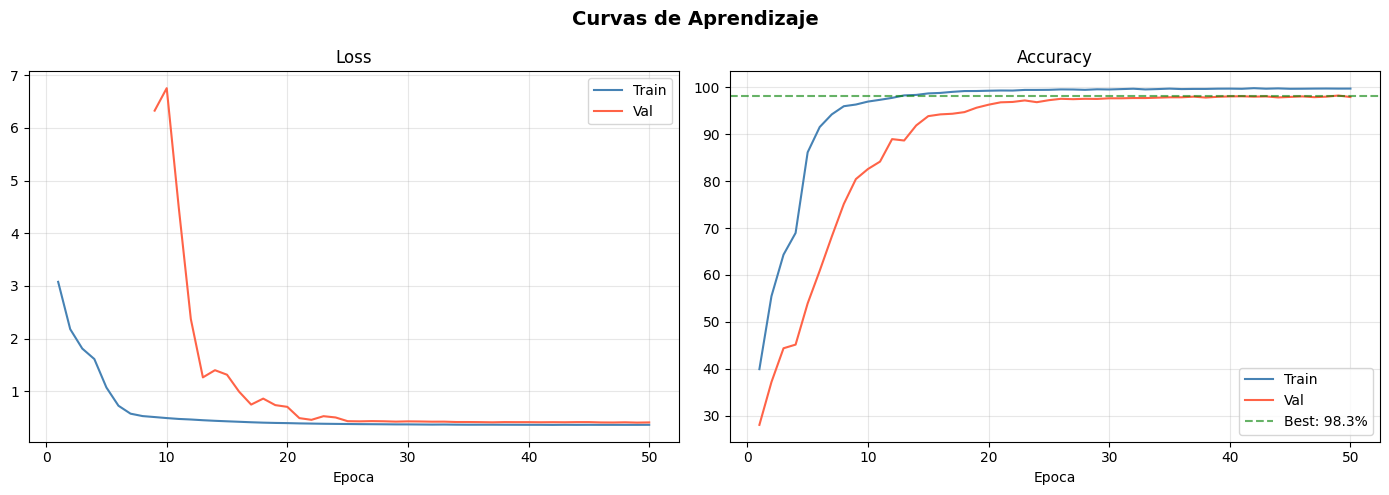

In [25]:
# CELDA 8 — CURVAS DE APRENDIZAJE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Curvas de Aprendizaje", fontsize=14, fontweight='bold')
ep = range(1, len(history['train_loss']) + 1)
axes[0].plot(ep, history['train_loss'], label='Train', color='steelblue')
axes[0].plot(ep, history['val_loss'],   label='Val',   color='tomato')
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoca"); axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(ep, [a*100 for a in history['train_acc']], label='Train', color='steelblue')
axes[1].plot(ep, [a*100 for a in history['val_acc']],   label='Val',   color='tomato')
axes[1].axhline(best_val_acc*100, color='green', linestyle='--', alpha=0.6,
               label=f'Best: {best_val_acc:.1%}')
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoca"); axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'curvas.png'), dpi=120, bbox_inches='tight')
plt.show()


              precision    recall  f1-score   support

    deportes      0.000     0.000     0.000         2
 entrevistas      0.000     0.000     0.000         2
     locutor      0.976     0.991     0.983      1910
      musica      0.990     0.976     0.983      1818

    accuracy                          0.983      3732
   macro avg      0.491     0.492     0.492      3732
weighted avg      0.982     0.983     0.982      3732



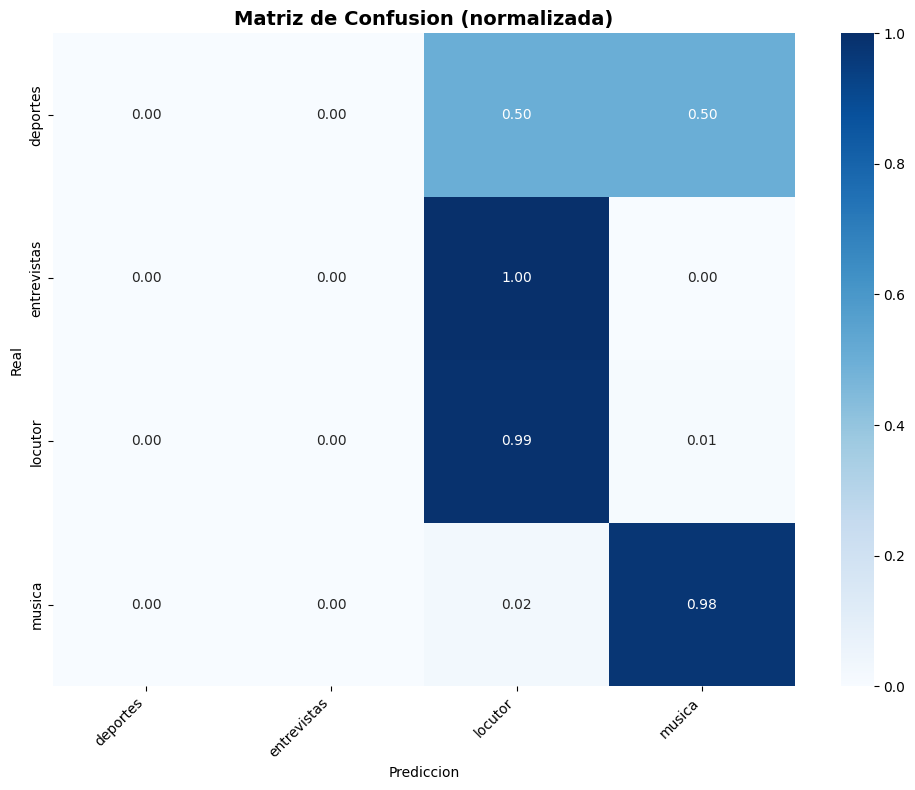

In [26]:
# CELDA 9 — MATRIZ DE CONFUSION Y CLASSIFICATION REPORT
import torch.nn.functional as F

checkpoint = torch.load(best_path, map_location=device)
model.load_state_dict(checkpoint['model_state'])
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for bx, by in val_loader:
        with autocast():
            out = model(bx.to(device))
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_labels.extend(by.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

labels_idx = list(range(N_CLASES))

print(classification_report(
    all_labels, all_preds,
    labels=labels_idx,
    target_names=CATEGORIAS,
    digits=3,
    zero_division=0
))

cm = confusion_matrix(all_labels, all_preds, labels=labels_idx).astype(float)
row_sums = cm.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1.0
cm_norm = cm / row_sums

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=CATEGORIAS, yticklabels=CATEGORIAS, ax=ax)
ax.set_title("Matriz de Confusion (normalizada)", fontsize=14, fontweight='bold')
ax.set_xlabel("Prediccion"); ax.set_ylabel("Real")
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig(os.path.join(MODEL_DIR, 'confusion.png'), dpi=120, bbox_inches='tight')
plt.show()
